## Monitoría SECOP 2 - Beca Avanza

### Análisis exploratorio de las variables predictoras

Notas de la reunión del 26/10. Las variables son las que entran a la red de `modelo_prorrogas.ipynb`, más los deltas de fechas de procesos competitivos, que se calculan pero no entran a la red. La exploración usa lo mismo que el cuaderno de regresión del curso (auto-mpg): `describe`, `pairplot`, matriz de correlación y `heatmap`.

Empecemos importando numpy, pandas, seaborn y matplotlib

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Carguemos el archivo prorrogas.csv (el mismo que usa el cuaderno del modelo)

In [2]:
df = pd.read_csv('../data/processed/prorrogas.csv')

In [3]:
df.head()

,mes_de_firma,modalidad_de_contratacion,tipo_de_contrato,justificacion_modalidad_de,nombre_entidad,tipodocproveedor,es_pyme,destino_gasto,origen_de_los_recursos,el_contrato_puede_ser_prorrogado,segmento_unspsc,log_precio_base,dias_firma_a_inicio,respuestas_al_procedimiento,dias_publicacion_a_firma,dias_entre_publicaciones,duracion_proceso,target
0,7,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.496238,6.0,0.0,5.440713,0.0,182.4,0
1,3,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.570543,0.0,0.0,0.956670,0.0,182.4,0
2,7,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.515344,0.0,0.0,2.963635,0.0,152.0,0
3,10,Contratación directa,Prestación de servicios,Servicios profesionales y apoyo a la gestión,AGENCIA NACIONAL DE TIERRAS - ANT,Cédula de Ciudadanía,No,Inversión,Distribuido,No,80,7.130334,1.0,0.0,4.109170,0.0,91.2,0
4,10,Contratación directa,Arrendamiento de inmuebles,Arrendamiento de inmuebles,AGENCIA PARA LA REINCORPORACIÓN Y LA NORMALIZA...,Cédula de Ciudadanía,No,Funcionamiento,Distribuido,No,80,7.808628,13.0,0.0,3.654366,0.0,395.2,0


Exploremos el tamaño del df

In [4]:
df.shape

(52999, 18)

Identificamos NAs en los datos

In [5]:
df.isna().sum()

mes_de_firma                          0
modalidad_de_contratacion             0
tipo_de_contrato                      0
justificacion_modalidad_de            0
nombre_entidad                        0
tipodocproveedor                      0
es_pyme                               0
destino_gasto                         0
origen_de_los_recursos                0
el_contrato_puede_ser_prorrogado      0
segmento_unspsc                       0
log_precio_base                     111
dias_firma_a_inicio                  78
respuestas_al_procedimiento          85
dias_publicacion_a_firma             85
dias_entre_publicaciones             85
duracion_proceso                     87
target                                0
dtype: int64

Definimos listas para las variables categóricas enteras, categóricas string y numéricas (las mismas del modelo)

In [6]:
cat_int_feats = ['mes_de_firma']

In [7]:
cat_str_feats = ['modalidad_de_contratacion', 'tipo_de_contrato', 'justificacion_modalidad_de',
                 'nombre_entidad', 'tipodocproveedor', 'es_pyme', 'destino_gasto',
                 'origen_de_los_recursos', 'el_contrato_puede_ser_prorrogado', 'segmento_unspsc']

In [8]:
num_feats = ['log_precio_base', 'dias_firma_a_inicio', 'respuestas_al_procedimiento',
             'dias_publicacion_a_firma', 'dias_entre_publicaciones', 'duracion_proceso']

## 1. Variable de respuesta

Proporción de contratos con prórroga (`target` = 1). La clase está desbalanceada: decir siempre "no" ya acierta la mayoría.

In [9]:
df['target'].value_counts()

target
0    46512
1     6487
Name: count, dtype: int64

In [10]:
df['target'].value_counts(normalize=True).round(3)

target
0    0.878
1    0.122
Name: proportion, dtype: float64

## 2. Variables numéricas

Estadísticas de cada variable numérica

In [11]:
df[num_feats].describe()

,log_precio_base,dias_firma_a_inicio,respuestas_al_procedimiento,dias_publicacion_a_firma,dias_entre_publicaciones,duracion_proceso
count,52888.000000,52921.000000,52914.000000,52914.000000,52914.000000,52912.000000
mean,7.603228,2.636042,0.041785,2.927772,0.065173,185.620277
std,0.398833,4.330364,0.786591,5.945532,1.253140,94.357260
min,5.780206,-3.000000,0.000000,0.003751,0.000000,0.000000
25%,7.409151,0.000000,0.000000,0.517827,0.000000,121.600000
50%,7.574031,2.000000,0.000000,1.110581,0.000000,182.400000
75%,7.737193,4.000000,0.000000,3.193408,0.000000,243.200000
max,12.418562,256.000000,52.000000,194.537142,103.858687,5502.400000


Mediana de cada variable numérica según si el contrato tuvo prórroga

In [12]:
df.groupby('target')[num_feats].median().T

target,0,1
log_precio_base,7.570543,7.604289
dias_firma_a_inicio,2.000000,1.000000
respuestas_al_procedimiento,0.000000,0.000000
dias_publicacion_a_firma,1.137715,0.989119
dias_entre_publicaciones,0.000000,0.000000
duracion_proceso,182.400000,182.400000


Tasa de prórroga por rangos (quintiles) de cada variable numérica

In [13]:
for col in num_feats:
    rangos = pd.qcut(df[col], 5, duplicates='drop')
    print(col)
    print(df.groupby(rangos, observed=True)['target'].agg(['count', 'mean']).round(3), '\n')

log_precio_base
                 count   mean
log_precio_base              
(5.779, 7.369]   10590  0.060
(7.369, 7.515]   10570  0.139
(7.515, 7.635]   10606  0.143
(7.635, 7.778]   10763  0.162
(7.778, 12.419]  10359  0.105 

dias_firma_a_inicio
                     count   mean
dias_firma_a_inicio              
(-3.001, 0.0]        13688  0.137
(0.0, 1.0]           11943  0.121
(1.0, 2.0]            7435  0.137
(2.0, 4.0]           10766  0.115
(4.0, 256.0]          9089  0.100 

respuestas_al_procedimiento
                             count   mean
respuestas_al_procedimiento              
(-0.001, 52.0]               52914  0.122 

dias_publicacion_a_firma
                          count   mean
dias_publicacion_a_firma              
(0.00275, 0.354]          10583  0.127
(0.354, 0.89]             10583  0.144
(0.89, 1.786]             10582  0.138
(1.786, 3.989]            10583  0.111
(3.989, 194.537]          10583  0.091 

dias_entre_publicaciones
                          count

Exploremos relaciones bivariadas con pairplot de seaborn, coloreando por `target` (muestra de 3.000 contratos para que la gráfica sea legible)

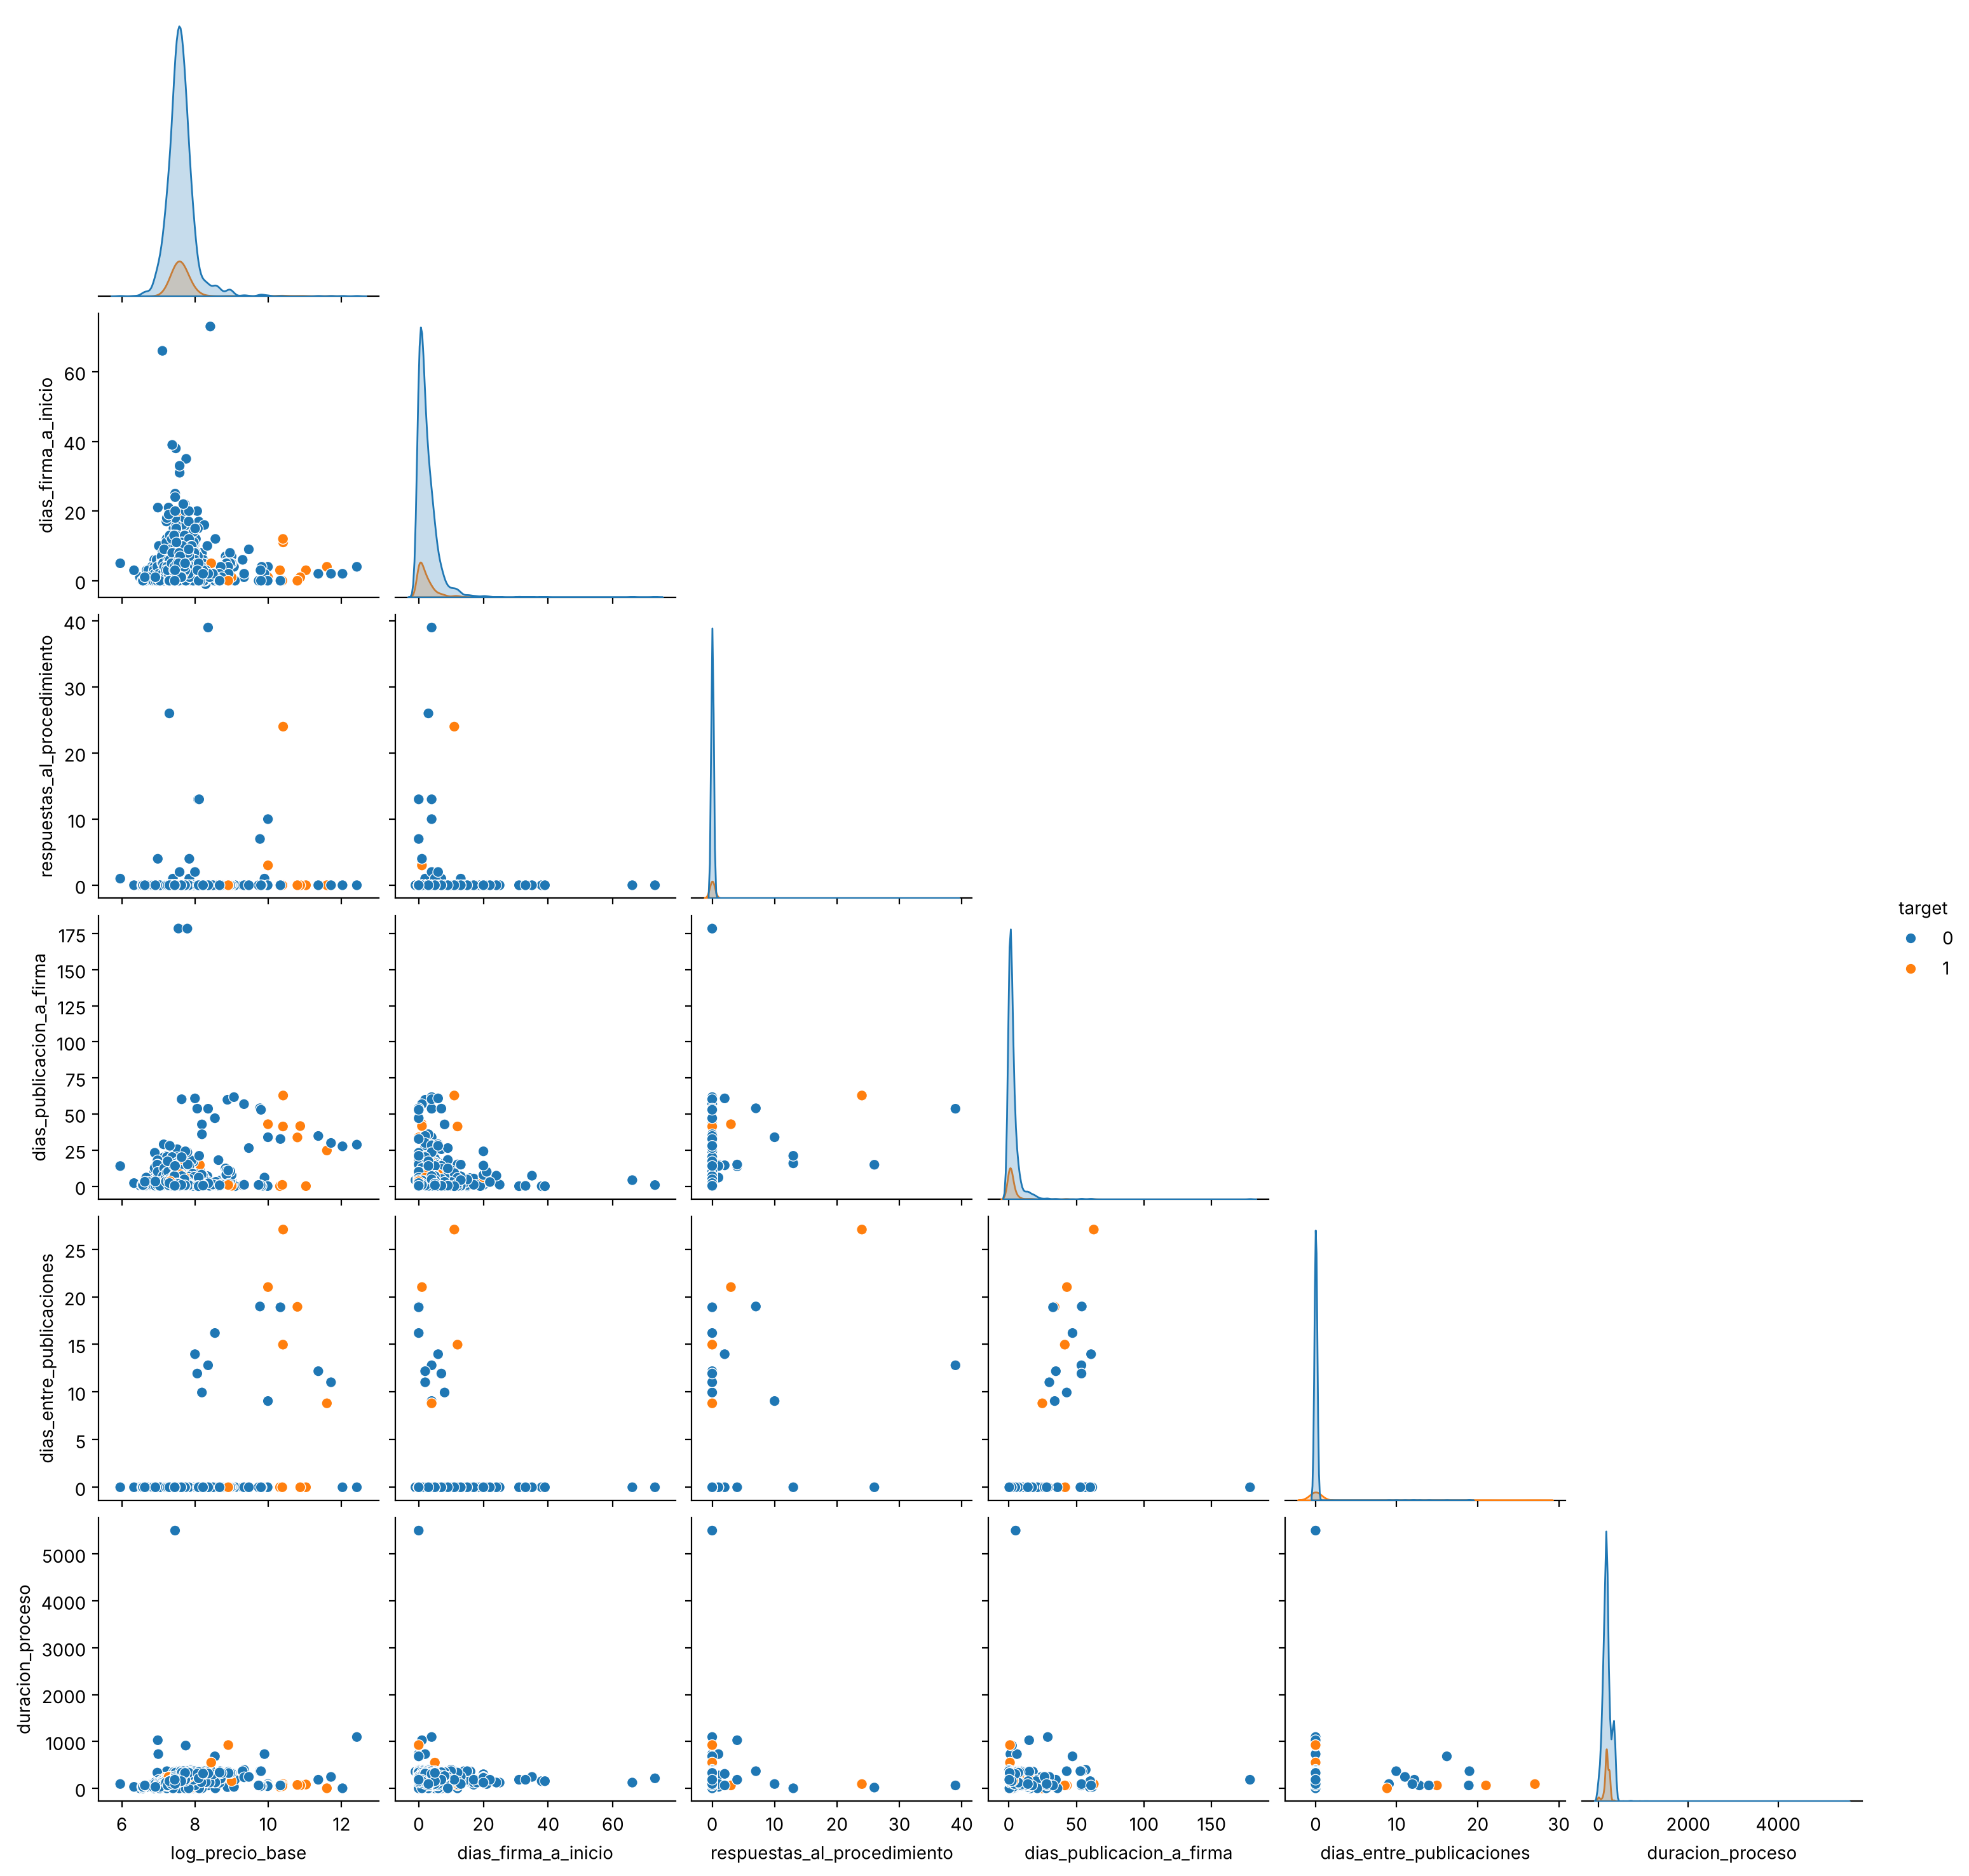

In [14]:
sns.pairplot(df.sample(3000, random_state=100)[num_feats + ['target']], hue='target', corner=True)

Calculemos la matriz de correlación de las variables numéricas y la respuesta

In [15]:
df[num_feats + ['target']].corr().round(3)

,log_precio_base,dias_firma_a_inicio,respuestas_al_procedimiento,dias_publicacion_a_firma,dias_entre_publicaciones,duracion_proceso,target
log_precio_base,1.000,0.048,0.129,0.211,0.284,0.438,0.042
dias_firma_a_inicio,0.048,1.000,0.035,0.090,0.025,0.050,-0.030
respuestas_al_procedimiento,0.129,0.035,1.000,0.274,0.376,-0.031,0.016
dias_publicacion_a_firma,0.211,0.090,0.274,1.000,0.438,-0.018,-0.023
dias_entre_publicaciones,0.284,0.025,0.376,0.438,1.000,0.000,0.037
duracion_proceso,0.438,0.050,-0.031,-0.018,0.000,1.000,0.012
target,0.042,-0.030,0.016,-0.023,0.037,0.012,1.000


<Axes: >

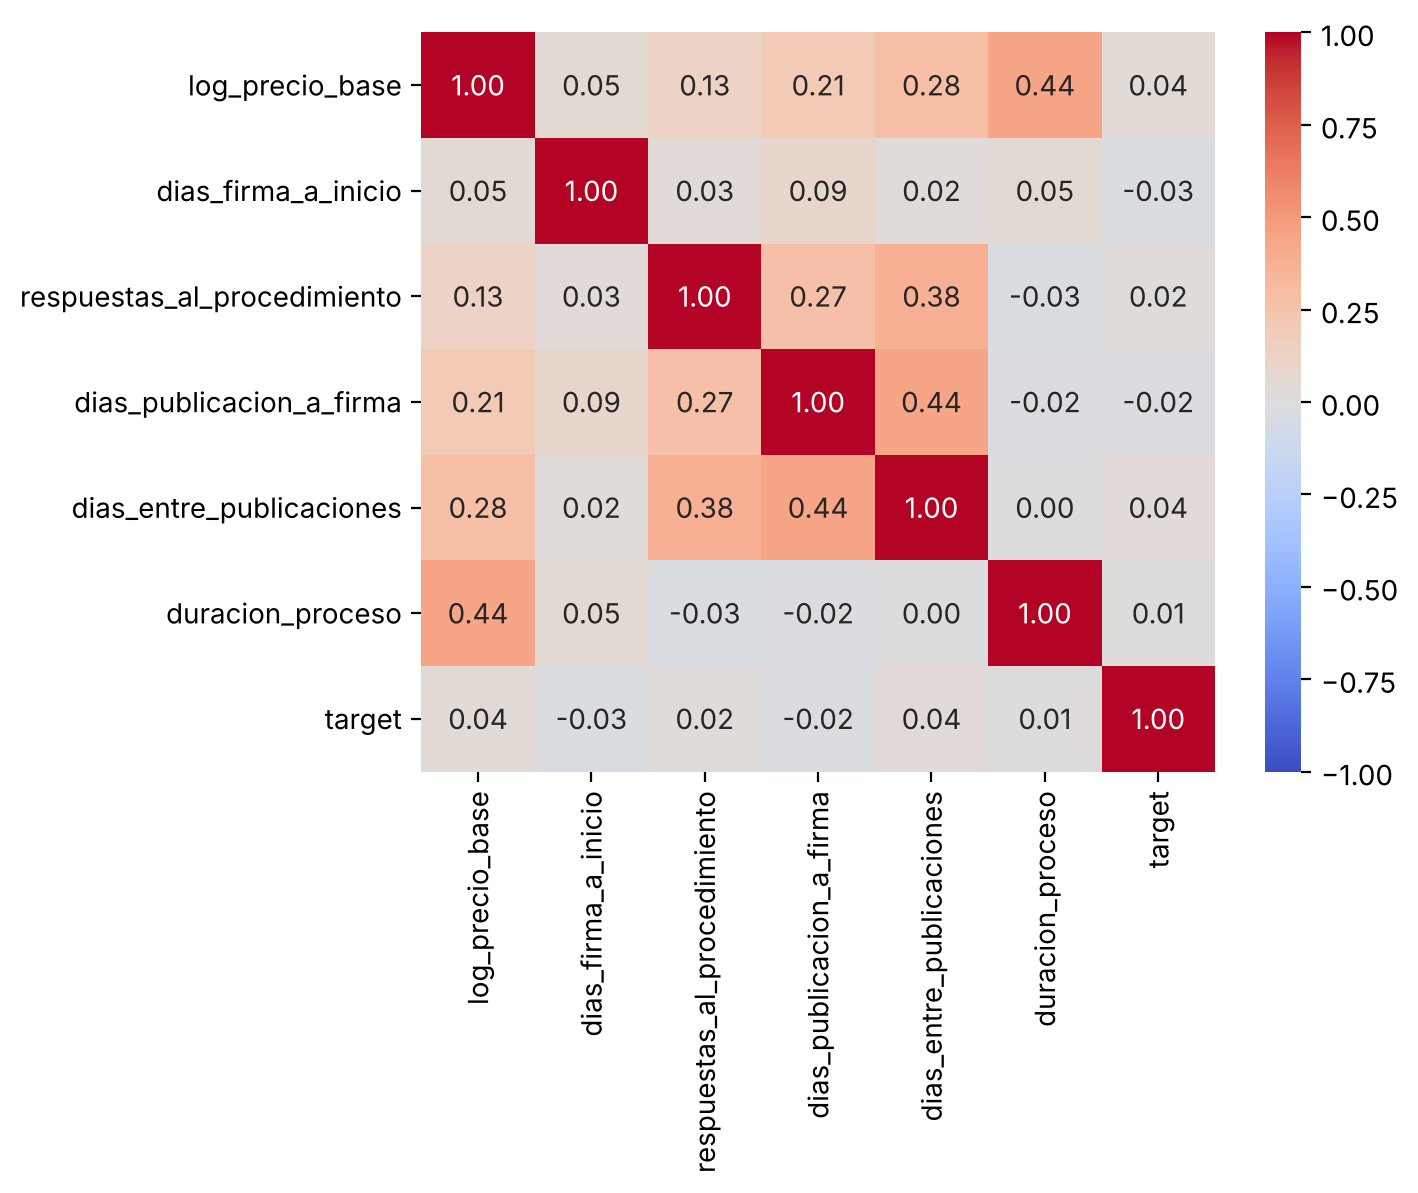

In [16]:
sns.heatmap(df[num_feats + ['target']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

Diagramas de caja de cada variable numérica según si hubo prórroga. Varias tienen valores extremos muy lejanos (la duración del proceso llega a 5.502 días), así que se grafica hasta el percentil 99 para que se vean las cajas; los valores extremos siguen en los datos.

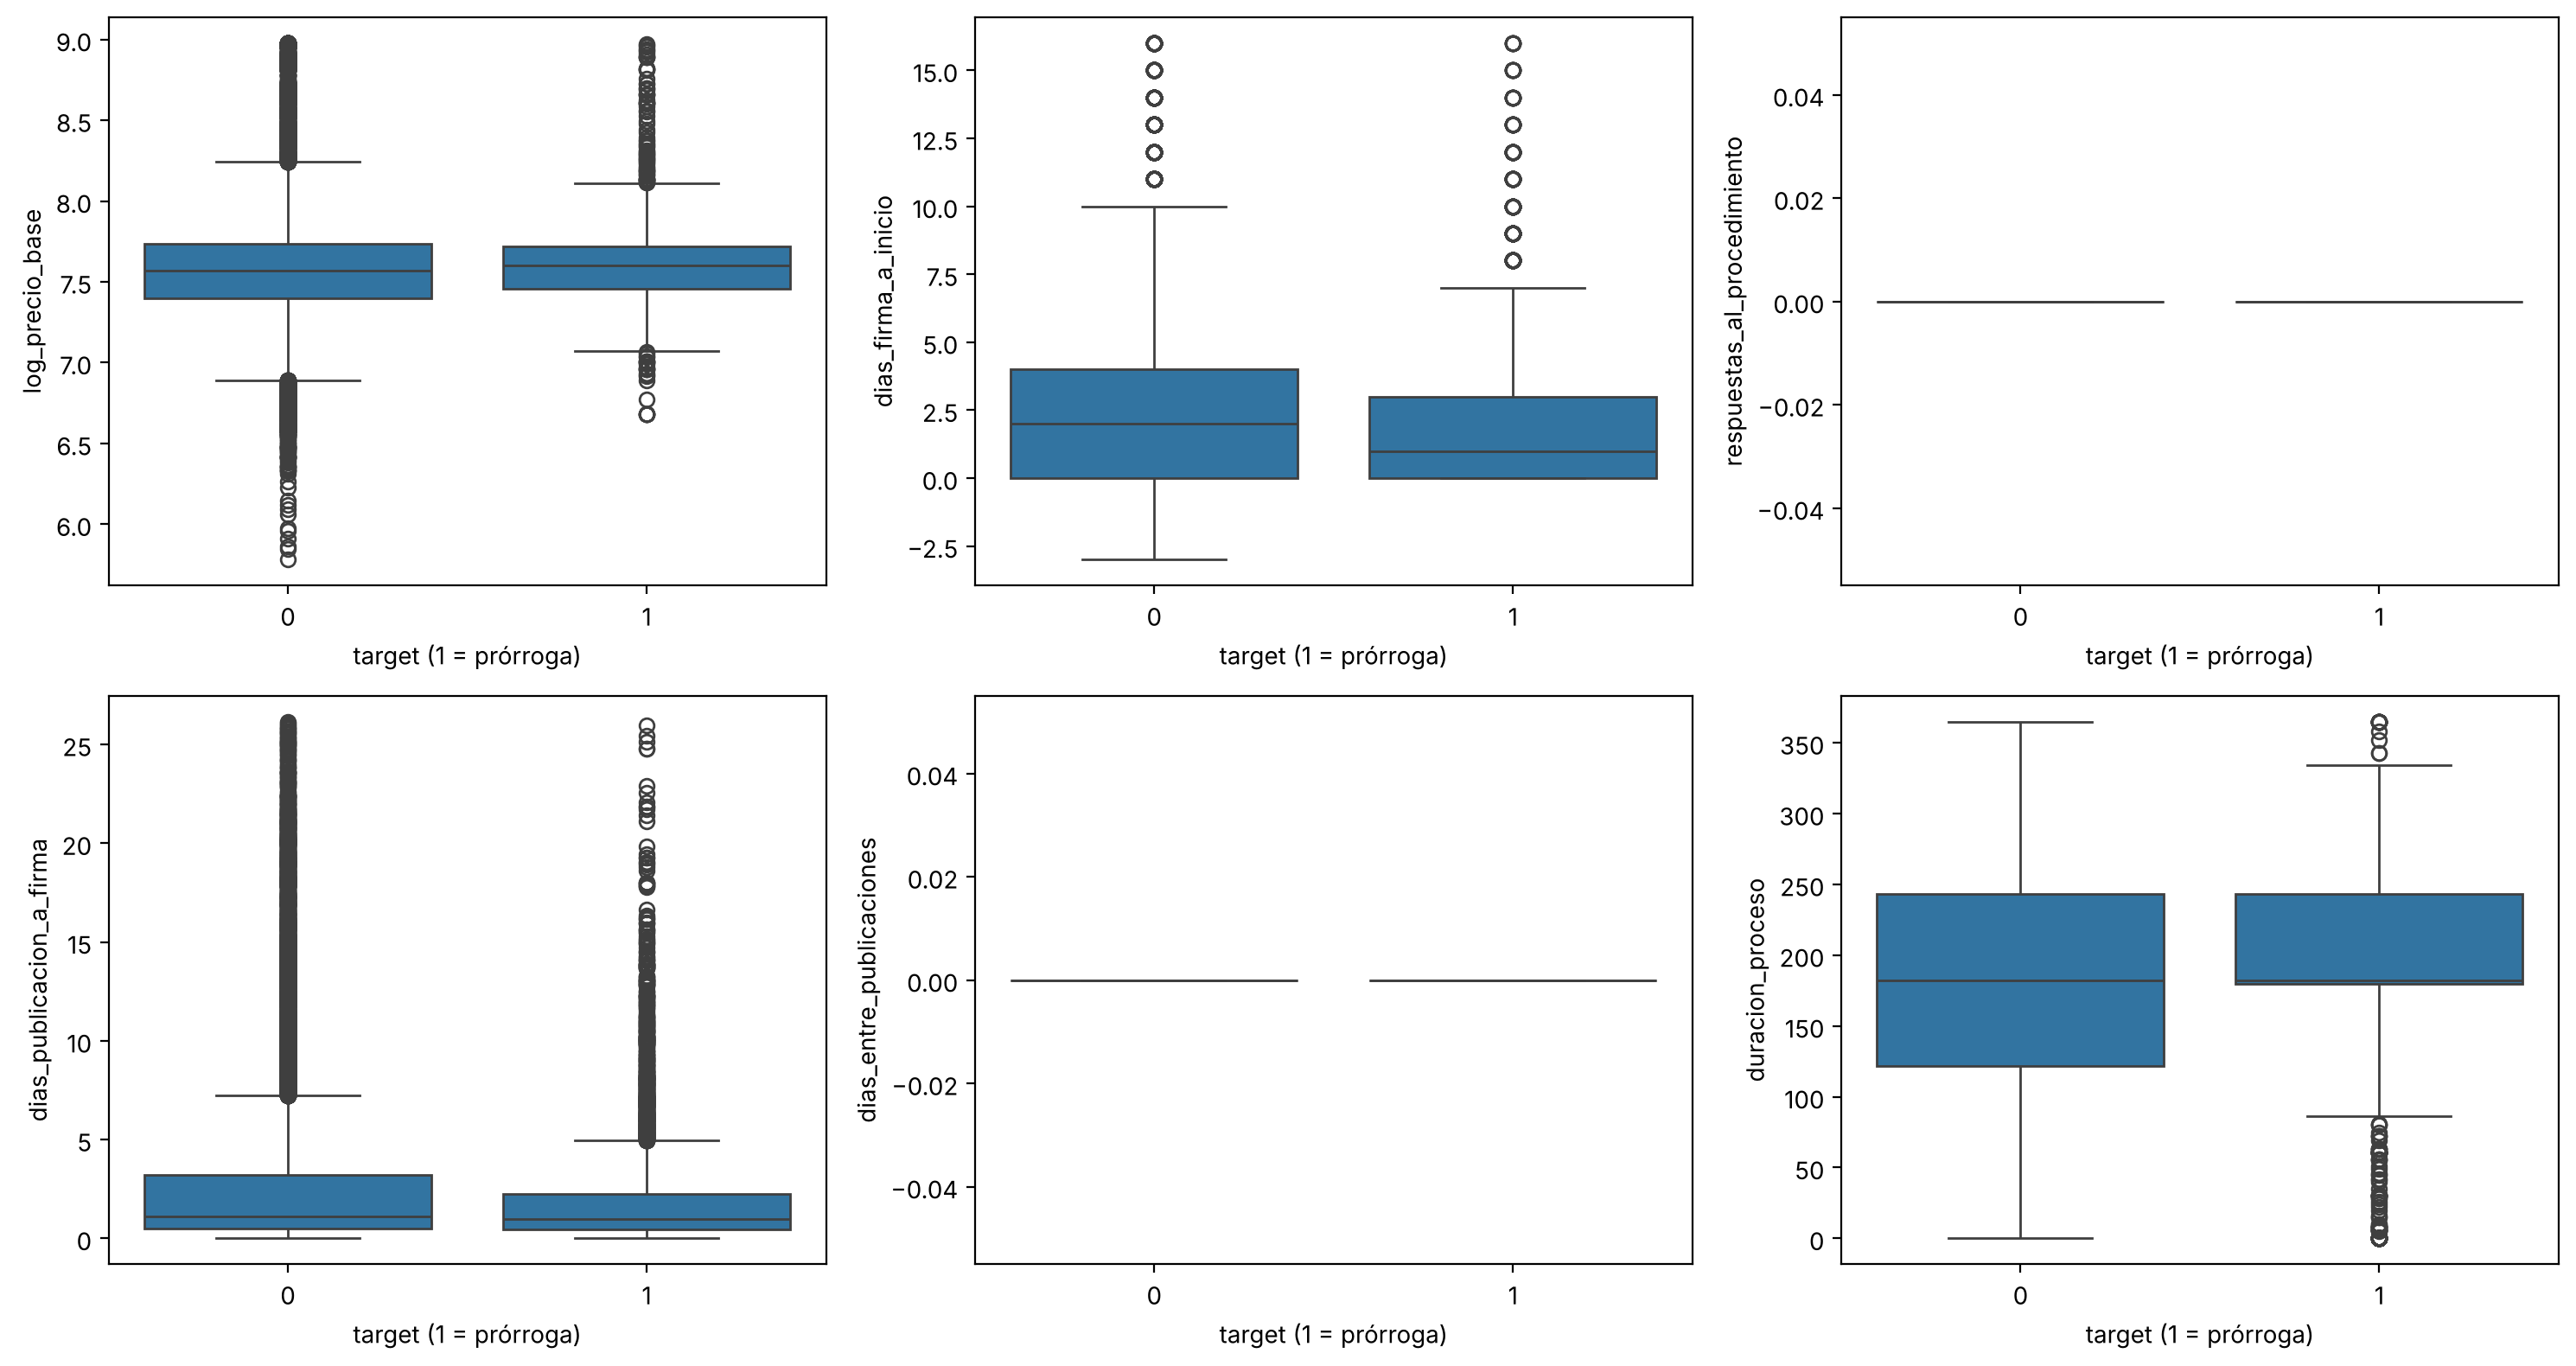

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_feats):
    tope = df[col].quantile(0.99)
    sns.boxplot(data=df[df[col] <= tope], x='target', y=col, ax=ax)
    ax.set_xlabel('target (1 = prórroga)')
plt.tight_layout()

Diagramas de violín: la misma comparación, mostrando la forma de la distribución

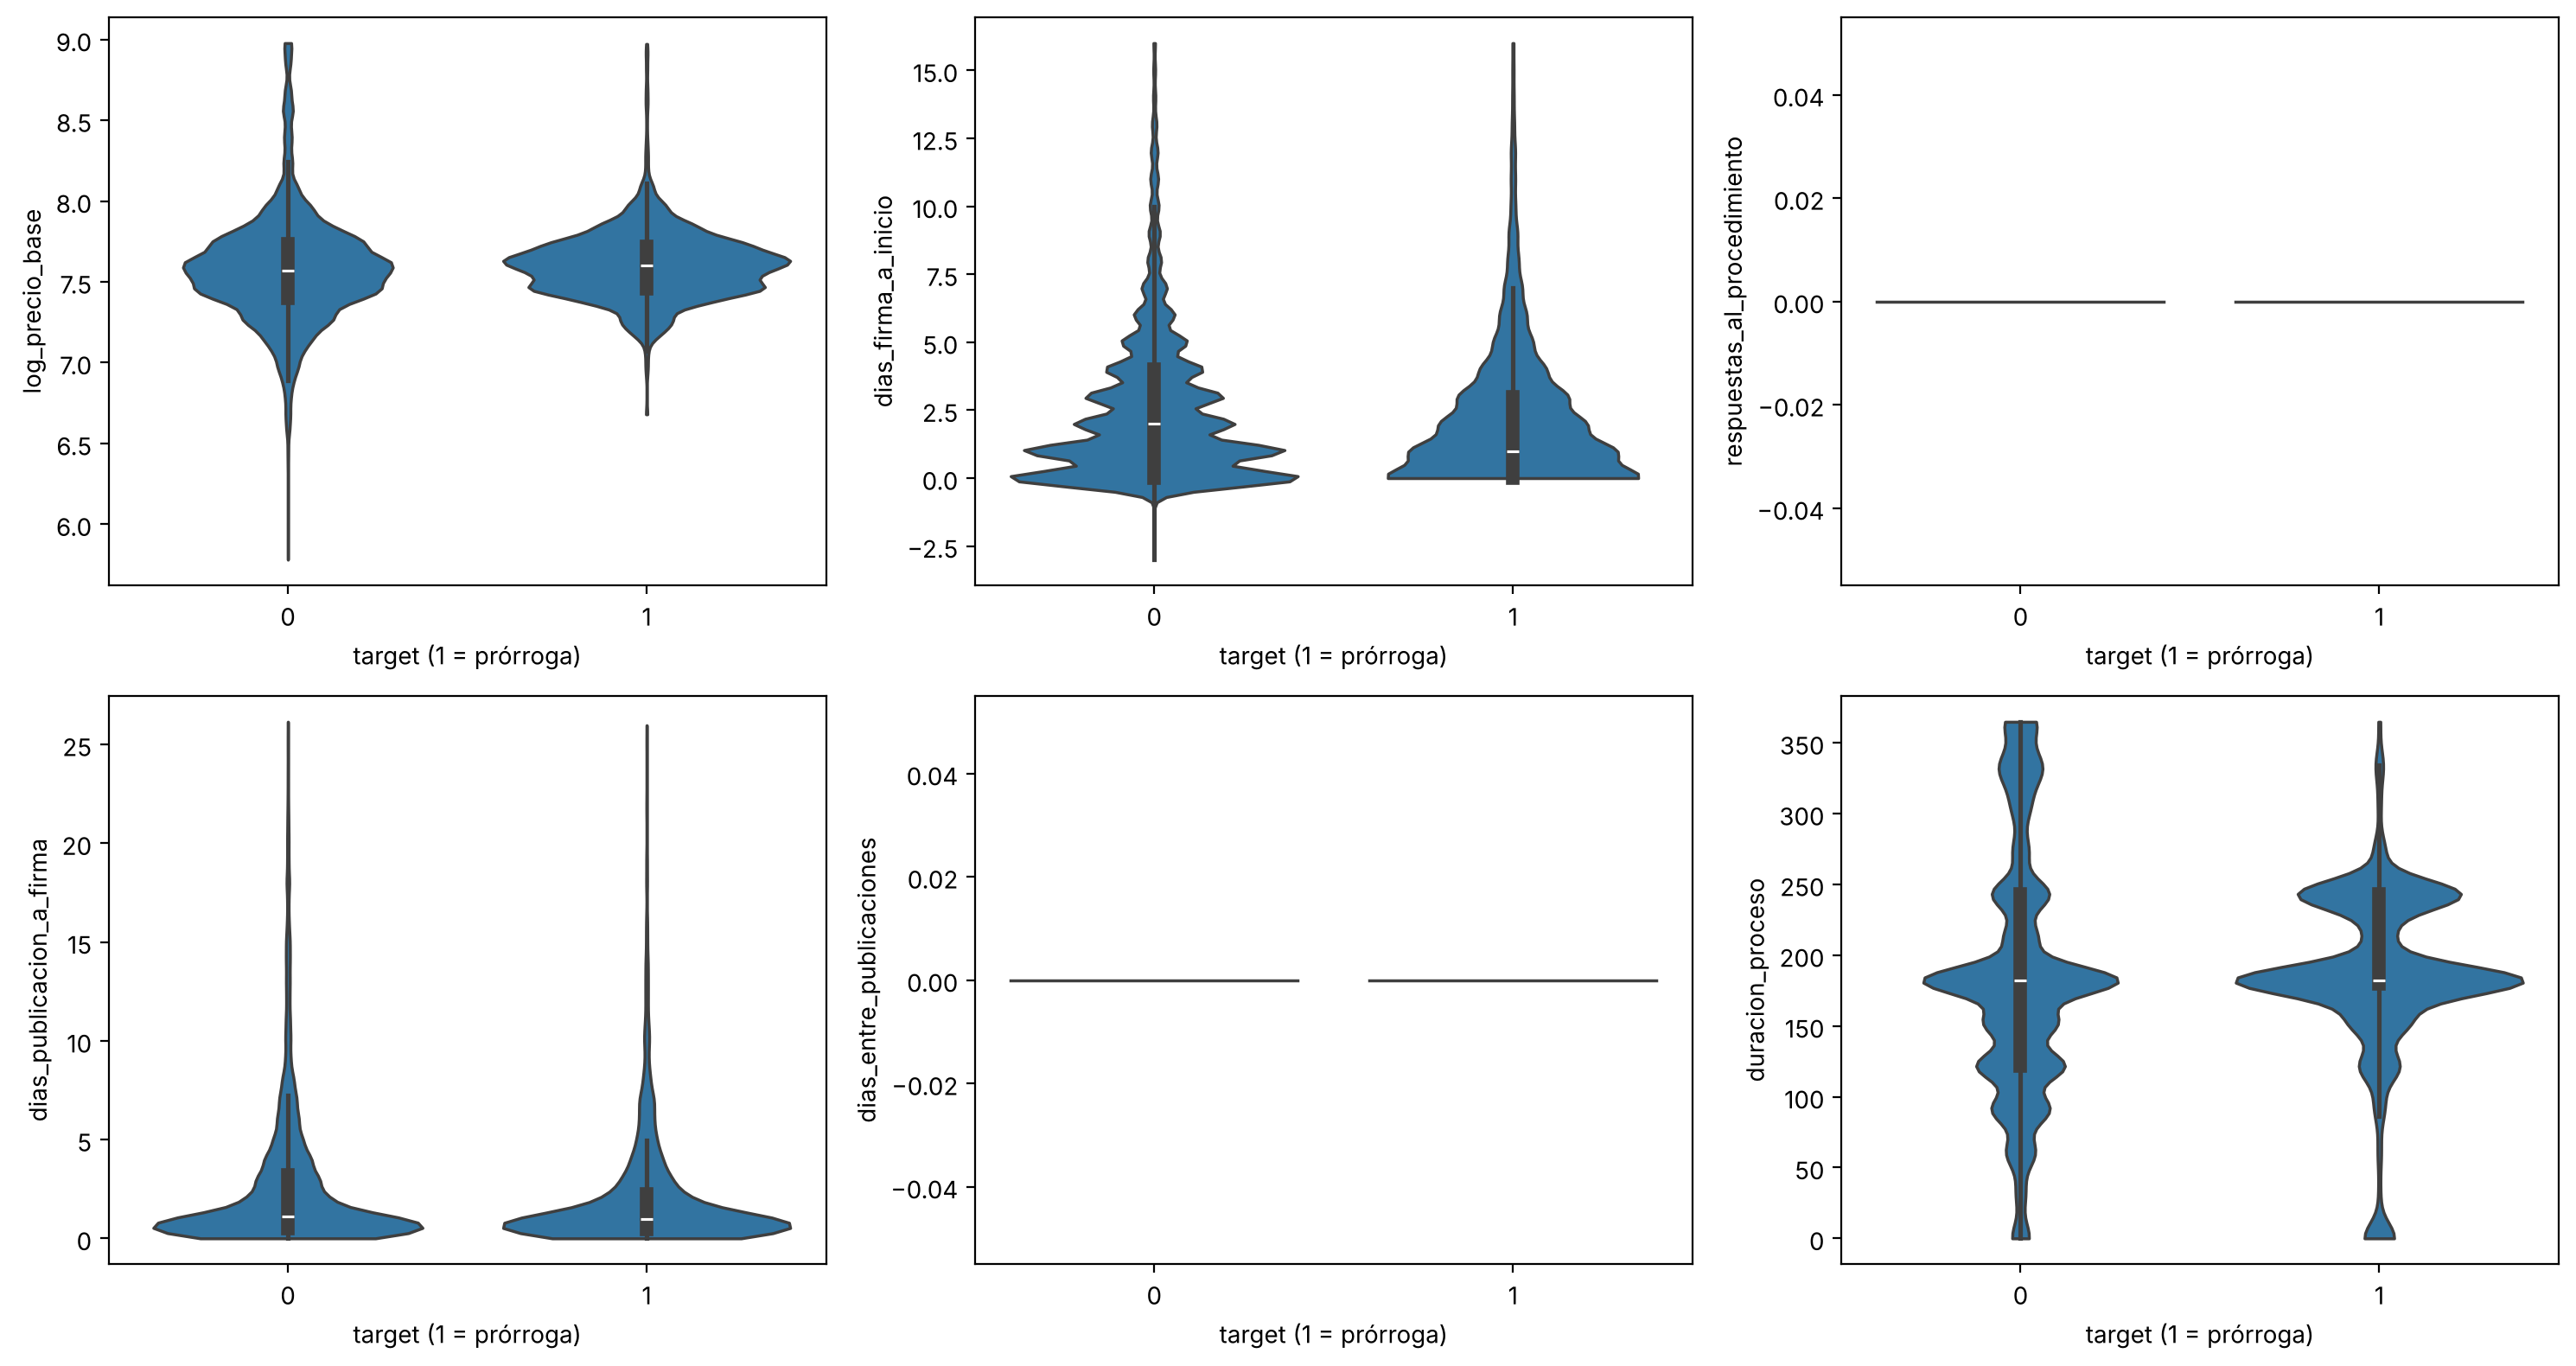

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_feats):
    tope = df[col].quantile(0.99)
    sns.violinplot(data=df[df[col] <= tope], x='target', y=col, ax=ax, cut=0)
    ax.set_xlabel('target (1 = prórroga)')
plt.tight_layout()

Histogramas de cada variable numérica según si hubo prórroga (densidad, para comparar grupos de distinto tamaño)

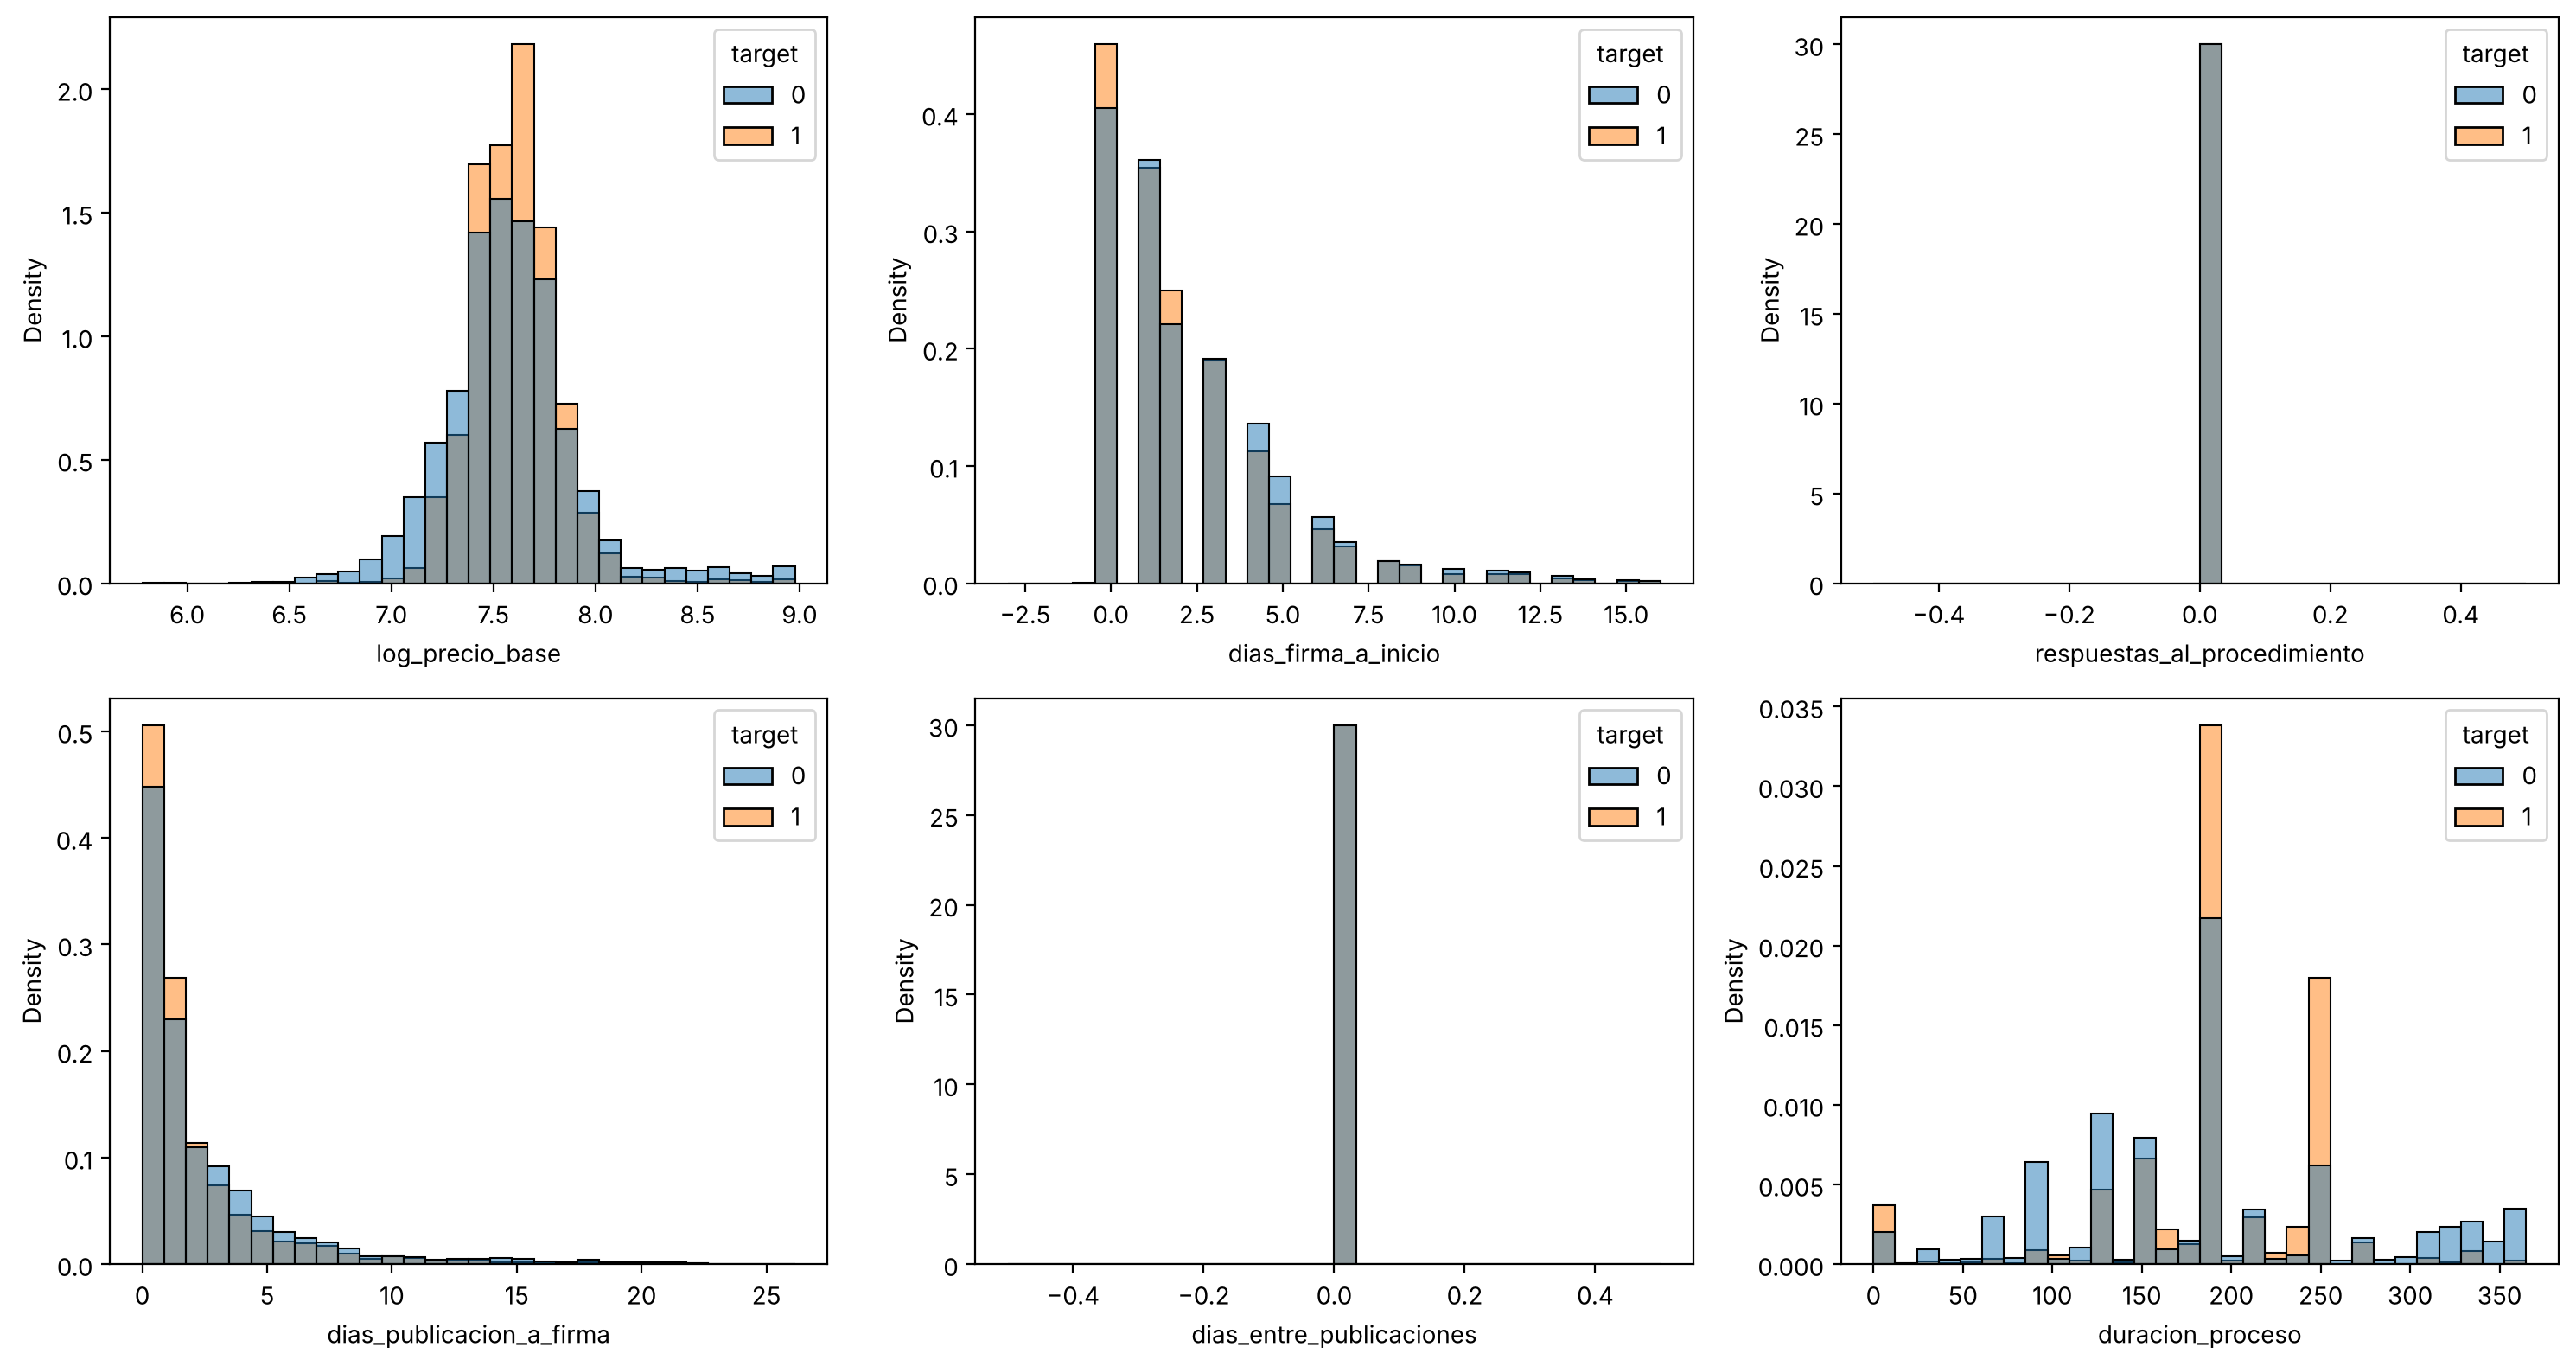

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_feats):
    tope = df[col].quantile(0.99)
    sns.histplot(data=df[df[col] <= tope], x=col, hue='target', stat='density',
                 common_norm=False, bins=30, ax=ax)
plt.tight_layout()

## 3. Variables categóricas

Tasa de prórroga (`mean`) y número de contratos (`count`) por categoría. Se muestran las 10 categorías con más contratos.

In [20]:
for col in cat_int_feats + cat_str_feats:
    tabla = df.groupby(col)['target'].agg(['count', 'mean']).sort_values('count', ascending=False)
    print(col, f'({df[col].nunique()} categorías)')
    print(tabla.head(10).round(3), '\n')

mes_de_firma (12 categorías)
              count   mean
mes_de_firma              
1             20369  0.216
2              5603  0.056
7              4677  0.027
9              3849  0.015
10             3847  0.006
8              3069  0.032
3              3013  0.069
5              2501  0.228
4              1886  0.137
11             1867  0.011 

modalidad_de_contratacion (10 categorías)
                                             count   mean
modalidad_de_contratacion                                
Contratación directa                         51625  0.122
Contratación régimen especial                  784  0.088
Mínima cuantía                                 194  0.067
Selección Abreviada de Menor Cuantía           192  0.234
Selección abreviada subasta inversa             96  0.250
Contratación Directa (con ofertas)              63  0.254
Licitación pública                              20  0.350
Concurso de méritos abierto                     14  0.143
Contratación régimen es

Tasa de prórroga por mes de firma

Text(0, 0.5, 'Tasa de prórroga')

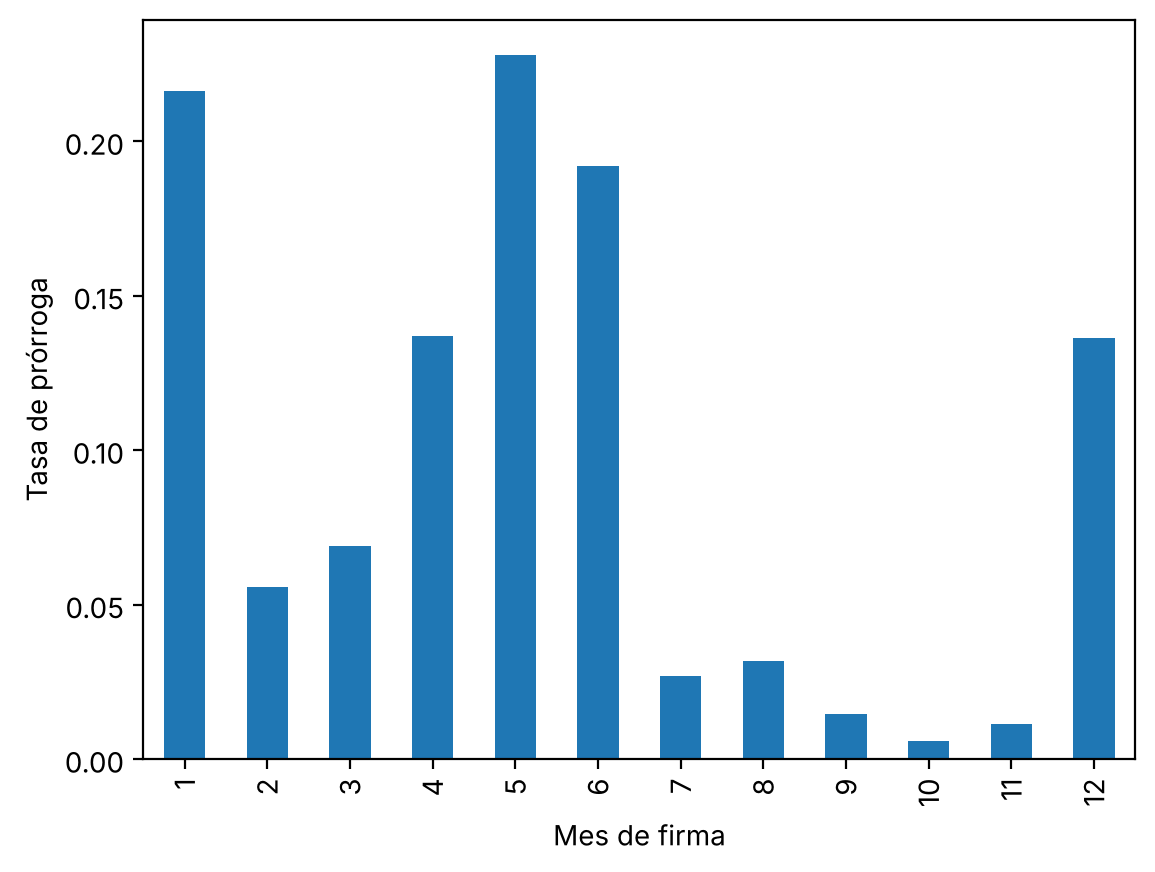

In [21]:
df.groupby('mes_de_firma')['target'].mean().plot.bar()
plt.xlabel('Mes de firma')
plt.ylabel('Tasa de prórroga')

## 4. Deltas de fechas de procesos competitivos

Publicación → cierre de ofertas → adjudicación → firma. Solo existen en procesos competitivos, así que no entran a la red: con `dropna` dejarían fuera casi todos los contratos. Se leen de la base completa con `preparar` del proyecto.

In [22]:
import sys
sys.path.append('..')
from src import modelos as mdl

base = pd.read_csv('../data/processed/base_prorrogas_ANT_UNP_ARN.csv.gz', low_memory=False)
tabla = mdl.preparar(base, fecha_corte='2026-11-23').rename(columns={'prorroga': 'target'})
comp = list(mdl.DELTAS_COMPETITIVOS)
tabla[comp].notna().mean().round(3)

dias_publicacion_a_recepcion     0.011
dias_recepcion_a_adjudicacion    0.011
dias_adjudicacion_a_firma        0.011
dtype: float64

In [23]:
tabla[comp].describe()

,dias_publicacion_a_recepcion,dias_recepcion_a_adjudicacion,dias_adjudicacion_a_firma
count,590.000000,584.000000,584.000000
mean,15.956179,12.524664,2.767351
std,12.116438,9.422765,3.368409
min,-2.549832,-3.412061,-6.264200
25%,6.574692,7.214409,0.806192
50%,16.626408,10.445640,1.722320
75%,23.802001,16.193514,4.014700
max,125.764827,61.390885,34.080395


In [24]:
tabla.dropna(subset=comp).groupby('target')[comp].median().T

target,0,1
dias_publicacion_a_recepcion,15.478253,21.584713
dias_recepcion_a_adjudicacion,10.220048,13.560135
dias_adjudicacion_a_firma,1.729037,1.019850


In [25]:
tabla.dropna(subset=comp)['target'].value_counts()

target
0    475
1    109
Name: count, dtype: int64

## 5. Variable excluida: duración del contrato (fin − inicio)

SECOP mueve la fecha de fin del contrato cuando hay prórroga. Comparando con la duración estimada del proceso, que se fija antes de firmar, se ve la diferencia: sin prórroga el contrato dura casi lo mismo que el proceso; con prórroga dura más, aproximadamente los días adicionados.

In [26]:
inicio = pd.to_datetime(base.loc[tabla.index, 'fecha_de_inicio_del_contrato'])
fin = pd.to_datetime(base.loc[tabla.index, 'fecha_de_fin_del_contrato'])
dias_adicionados = pd.to_numeric(base.loc[tabla.index, 'dias_adicionados'])
comparacion = pd.DataFrame({
    'contrato_menos_proceso': (fin - inicio).dt.days - tabla['duracion_proceso'],
    'contrato_menos_proceso_y_adicion': (fin - inicio).dt.days - tabla['duracion_proceso'] - dias_adicionados,
    'target': tabla['target'],
})
comparacion.groupby('target').median().round(1)

,contrato_menos_proceso,contrato_menos_proceso_y_adicion
target,,
0,-13.8,-13.8
1,69.0,-17.4


### Lectura de los resultados

**Base:** 52.999 contratos de prestación de servicios (ANT, UNP, ARN) con fecha de fin ya cumplida; 12,2 % tuvo prórroga.

**Variables categóricas (tasas por categoría)**

- **Mes de firma:** enero 21,6 % y mayo 22,8 %; de julio a noviembre 0,6 – 3,2 %.
- **Entidad:** UNP 26,7 %, ANT 10,2 %, ARN 1,4 %.
- **Destino del gasto:** funcionamiento 17,0 %, inversión 9,9 %.
- Origen de los recursos y es PYME casi no cambian la tasa entre categorías.

**Variables numéricas (medianas, quintiles, cajas, violín, histogramas)**

- **Duración del proceso:** los procesos de 180 – 243 días tienen 18 – 24 % de prórroga; los de más de 243 días, 3 %.
- **Precio base (log):** el quintil más bajo tiene 6 % de prórroga.
- **Días de firma a inicio:** mediana 1 día con prórroga vs 2 sin prórroga.
- **Respuestas al procedimiento** y **días entre publicaciones** son casi siempre 0 (contratación directa), así que aportan poco.
- Las correlaciones con la variable objetivo son todas menores a 0,05: las diferencias no son lineales y se ven mejor en las tasas por quintiles.

**Deltas de procesos competitivos (≈ 1 % de las filas)**

- Con prórroga los procesos tardan más de publicación a cierre de ofertas (mediana 21,6 vs 15,5 días) y de cierre a adjudicación (13,6 vs 10,2 días).
- Por la poca cantidad de datos no entran a la red (el `dropna` eliminaría el 99 % de las filas).

**Variable excluida**

- Sin prórroga, la duración del contrato es casi la del proceso (−13,8 días); con prórroga es 69 días mayor; si se descuentan los días adicionados queda en −17,4.
- Esto confirma que la fecha de fin ya incluye la prórroga, por eso se excluye del modelo.

**Para el modelo**

- Las variables con más señal son **mes de firma, entidad, destino del gasto y duración del proceso**.